# Definições contínuas 1D

## Convolução

$$(f * g)(x) = \int_{-\infty}^{\infty} f(y)g(x-y)\, \mathrm{dy}$$

### Circular

$$(f \circledast g)(x) = \int_{0}^{T} f(y)g(x-y)\, \mathrm{dy}$$

## Transformada de Fourier

$$\mathcal F \{f(x)\}(\omega) = \int_{-\infty}^{\infty} f(x)e^{-i\omega x}\, \mathrm{dx}$$

# Definições discretas 1D

## Convolução

$$(f * g)[n] = \sum_{m=-\infty}^{\infty} f[m] \, g[n-m]$$

### Circular

$$(f \circledast g)[n] = \sum_{m=0}^{N-1} f[m] \, g[(n-m)\quad (\mathrm{mod} N)]$$


## Transformada de Fourier

$$\mathcal F \{f[n]\}(\omega) = \sum_{n=-\infty}^{\infty} f[n] \, e^{-i\omega n}$$

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import convolve
from scipy.fft import fft, ifft

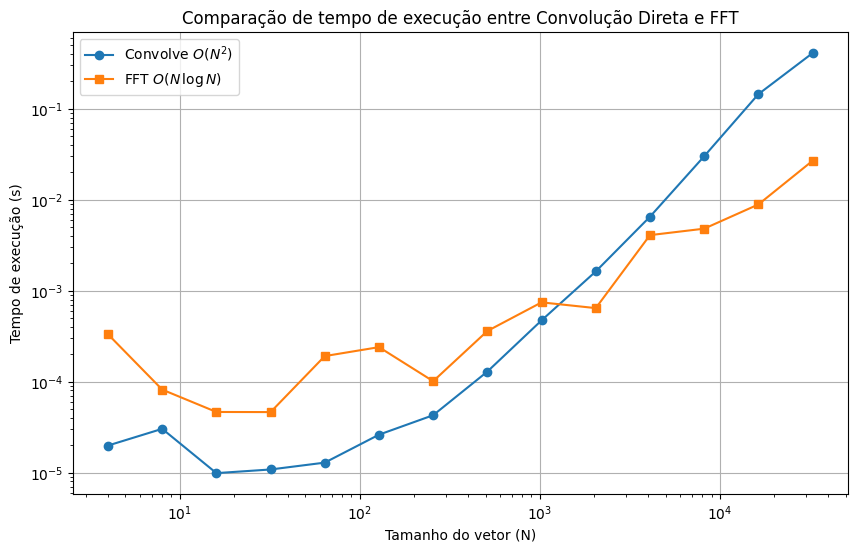

In [2]:
Nvec = [2**k for k in range(2, 16)]

t_conv = []
t_fft = [] # Fast Fourier Transform

repeticoes = 30

for N in Nvec:
    f = np.random.randn(N)
    g = np.random.randn(N)

    tempos = []
    for _ in range(repeticoes):
        inicio = time.perf_counter()
        res_conv = convolve(f, g, mode='full', method='direct')
        tempos.append(time.perf_counter() - inicio)

    t_conv.append(np.mean(tempos))

    tempos = []
    for _ in range(repeticoes):
        inicio = time.perf_counter()

        N_fft = 2*N-1
        F = fft(f, n=N_fft)
        G = fft(g, n=N_fft)
        res_fft = np.real(ifft(F*G))

        tempos.append(time.perf_counter() - inicio)

    t_fft.append(np.mean(tempos))

plt.figure(figsize=(10,6))

plt.loglog(Nvec, t_conv, 'o-', label=r'Convolve $O(N^2)$')
plt.loglog(Nvec, t_fft, 's-', label=r'FFT $O(N\, \log N)$')

plt.title('Comparação de tempo de execução entre Convolução Direta e FFT')
plt.xlabel('Tamanho do vetor (N)')
plt.ylabel('Tempo de execução (s)')
plt.grid()
plt.legend()

plt.show()